In [1]:
import os
import sys

sys.path.append("../src")
from training.plot import (
    plot_variance_per_feature,
    plot_average_feature_variance,
    plot_overall_ensemble_variance,
)
from data_processing.utils import compute_ensemble_variance_by_lead_time
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from data_processing.load import load_windpower
from data_processing.downtime import CapacityFactorTransformer
import pandas as pd

from data_processing.load import (
    load_windparks,
    load_windparks,
    load_weather_forecast_parquet,
    load_windpower,
    load_weather_nowcast,
)
import pandas as pd

from data_processing.load import (
    load_weather_forecast_parquet,
    load_windpower,
    load_weather_nowcast,
)

from data_processing.load import load_dataset
from configs.load_config import dict_to_namespace
from scipy.stats import spearmanr
import numpy as np

Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)


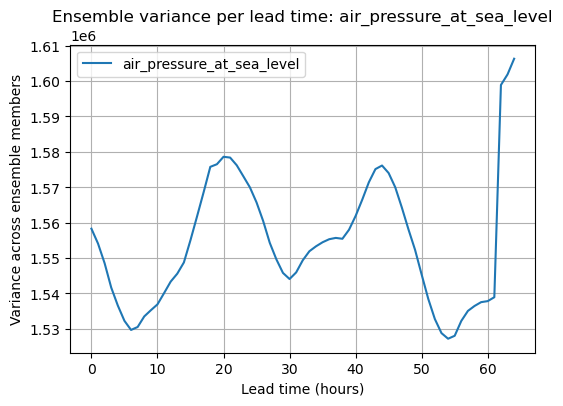

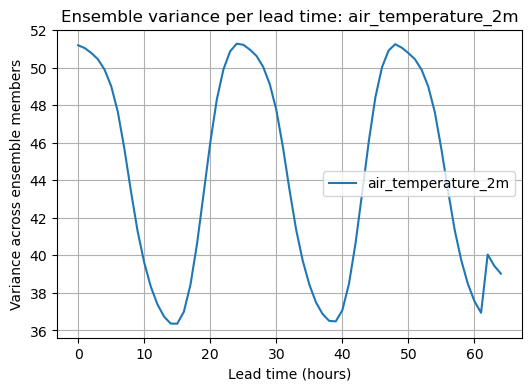

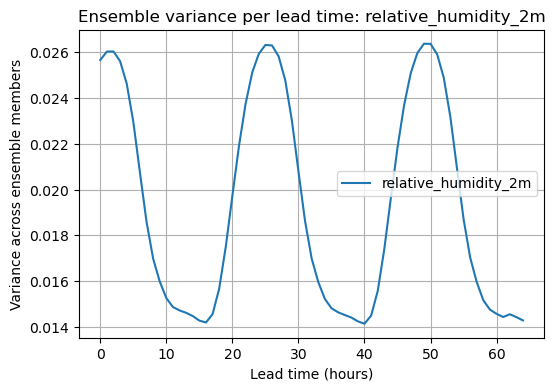

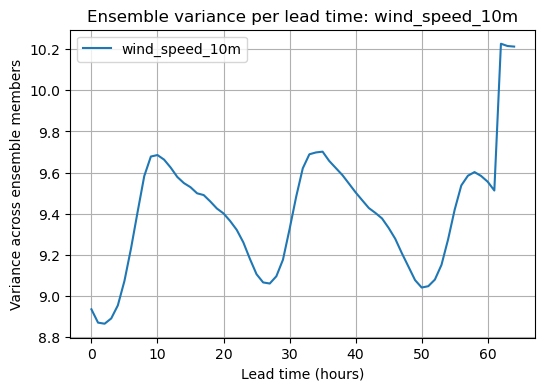

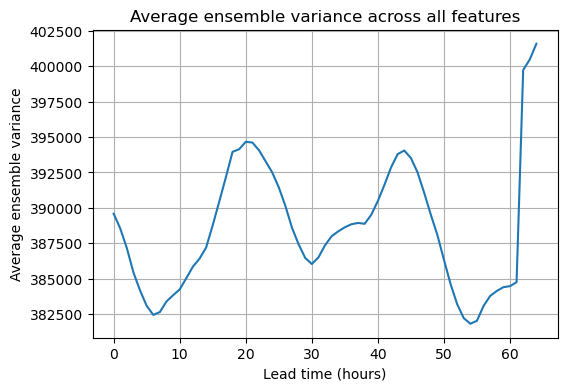

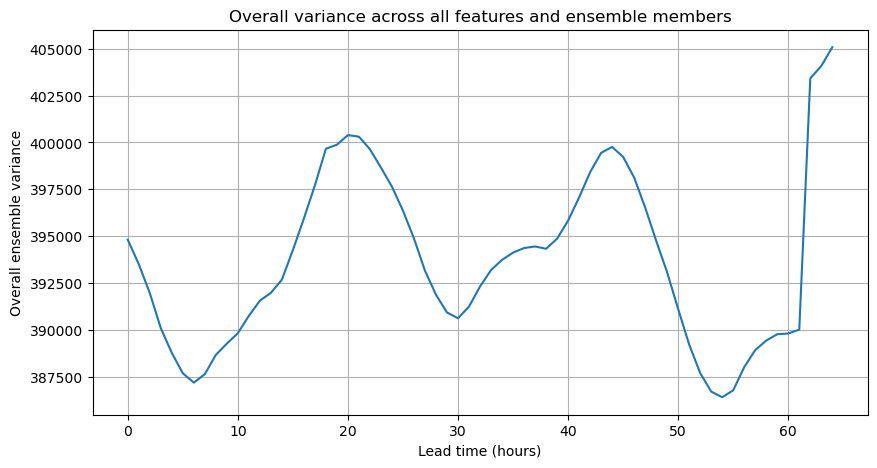

In [2]:
var_by_feature, var_overall_features, overall_variance = (
    compute_ensemble_variance_by_lead_time()
)

plot_variance_per_feature(var_by_feature)
plot_average_feature_variance(var_overall_features)
plot_overall_ensemble_variance(overall_variance)

UMM maintenance events, calculate fraction per bidding zone


In [3]:
data_path = "../data"
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")

BIDZONES = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
capacity_factor_transformer = CapacityFactorTransformer()
maintenance_events = capacity_factor_transformer.maintenance_events.copy()


def hourly_range_inclusive(start, stop):
    return pd.date_range(start, stop, freq="h", inclusive="both")


# Pro Event: Stundenliste erzeugen, dann explodieren
maintenance_events["time"] = maintenance_events.apply(
    lambda r: hourly_range_inclusive(r["Event Start"], r["Event Stop"]), axis=1
)

maintenance_hours_long = (
    maintenance_events[["Area", "time"]]
    .explode("time")
    .drop_duplicates()
    .loc[lambda df: df["time"].isin(windpower.index)]
    .sort_values(["time", "Area"])
    .reset_index(drop=True)
)
# Zeitfenster (stündlich, inkl. beider Enden)
t0 = windpower.index.min()
t1 = windpower.index.max()
all_hours = pd.date_range(t0, t1, freq="h", inclusive="both")
total_hours = len(all_hours)
missing_in_power = all_hours.difference(windpower.index)
print(f"Missing hours in windpower: {len(missing_in_power)}")

# nur maintenance-stunden im selben fenster
mh = maintenance_hours_long.copy()
mh = mh[mh["time"].between(t0, t1)]

# Anzahl maintenance-stunden pro Area
counts = mh.groupby("Area")["time"].nunique().reindex(BIDZONES, fill_value=0)

# Ergebnis: count + fraction
maintenance_summary = (
    pd.DataFrame({"maintenance_hours": counts})
    .assign(total_hours=len(windpower.index))
    .assign(fraction=lambda d: d["maintenance_hours"] / d["total_hours"])
)

print(maintenance_summary)
print(windpower.index, len(windpower))

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Missing hours in windpower: 54
            maintenance_hours  total_hours  fraction
Area                                                
ELSPOT NO1               5932        46011  0.128926
ELSPOT NO2                510        46011  0.011084
ELSPOT NO3               1540        46011  0.033470
ELSPOT NO4               2710        46011  0.058899
DatetimeIndex(['2020-01-01 01:00:00+01:00', '2020-01-01 02:00:00+01:00',
               '2020-01-01 03:00:00+01:00', '2020-01-01 04:00:00+01:00',
               '2020-01-01 05:00:00+01:00', '2020-01-01 06:00:00+01:00',
               '2020-01-01 07:00:00+01:00', '2020-01-01 08:00:00+01:00',
               '2020-01-01 09:00:00+01:00', '2020-01-01 10:00:00+01:00',
               ...
               '2025-04-03 01:00:00+02:00', '2025-04-03 02:00:00+02:00',
               '2025-04-03 03:00:00+02:00', '2025-04-03 04:00:00+02:00',
               '2025-04-03 05:00:00+02:00', '2025-04-03 06:00:00+02:00',
               '2025-04-03 07:00:00+02:00', '202

In [4]:
missing_in_power = all_hours.difference(windpower.index)
extra_in_power = windpower.index.difference(all_hours)

In [5]:
len(missing_in_power), len(windpower.index), len(all_hours)

(54, 46011, 46065)

In [6]:
windparks = load_windparks("../data/windparks_bidzone.csv")
# 1) Substation / Windpark Ebene
substation_summary = windparks.groupby(
    ["bidding_area", "substation_name"], as_index=False
).agg(
    prod_start_new=("prod_start_new", "max"),
    operating_power_max=("operating_power_max", "mean"),
    n_units=("substation_name", "size"),
)

# 2) Bidding Area Ebene (aus Substations!)
summary = (
    substation_summary.groupby("bidding_area")
    .agg(
        prod_start_all_operational=("prod_start_new", "max"),
        n_windparks=("substation_name", "count"),  # jetzt eindeutig!
        max_capa=("operating_power_max", "sum"),
    )
    .sort_index()
)

summary

,prod_start_all_operational,n_windparks,max_capa
bidding_area,,,
ELSPOT NO1,2022-10-26 22:00:00,6,405.7
ELSPOT NO2,2024-09-09 23:00:00,20,1451.3
ELSPOT NO3,2022-10-12 12:00:00,25,2120.4
ELSPOT NO4,2022-11-29 15:00:00,14,1160.0


weather forecast and nowcast of 4 windparks is missing

- two in NO2
- one in NO3
- one in NO4

(renaming of two in nowcast)


In [7]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
meta_parks = pd.Index(windparks["substation_name"].dropna().unique())

forecast_parks = pd.Index(weather_forecast["sid"].dropna().unique())
nowcast_parks = pd.Index(weather_nowcast["windpark"].dropna().unique())

missing_in_forecast = meta_parks.difference(forecast_parks)
missing_in_nowcast = meta_parks.difference(nowcast_parks)

missing_in_parks_f = forecast_parks.difference(meta_parks)
missing_in_parks_n = nowcast_parks.difference(meta_parks)

print(f"forecast: {missing_in_forecast, missing_in_parks_f}")
print(f"nowcast: {missing_in_nowcast, missing_in_parks_n}")

forecast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))
nowcast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))


datasets start and end dates

- nowcast: '2020-01-01 01:00:00+0100' to '2025-04-01 01:00:00+0200'
- forecast: '2020-02-17 00:00:00+0100' to '2025-03-26 23:00:00+0100'
- windpower: '2020-01-01 01:00:00+0100' to '2025-04-03 10:00:00+0200'


In [8]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")


# Keep only two day ahead entries
forecast_day = weather_forecast["time"].dt.floor("D")
ref_day_plus_2 = weather_forecast["time_ref"].dt.floor("D") + pd.Timedelta(days=2)
weather_forecast_filtered = weather_forecast.loc[forecast_day == ref_day_plus_2].copy()
print(f"After 2-day ahead filtering: {len(weather_forecast_filtered)} rows")
print(
    f"Lead time range: {weather_forecast_filtered['lt'].min():.1f}h "
    f"to {weather_forecast_filtered['lt'].max():.1f}h"
)

forecast_times = pd.Index(weather_forecast_filtered["time"].unique())
nowcast_times = weather_nowcast.index

non_overlapping_f = forecast_times.difference(nowcast_times)
non_overlapping_n = nowcast_times.difference(forecast_times)

print(non_overlapping_f, "\n", non_overlapping_n)

After 2-day ahead filtering: 2592073 rows
Lead time range: 34.0h to 61.0h
DatetimeIndex(['2024-08-21 00:00:00+02:00'], dtype='datetime64[ns, CET]', freq=None) 
 DatetimeIndex(['2020-01-01 01:00:00+01:00', '2020-01-01 02:00:00+01:00',
               '2020-01-01 03:00:00+01:00', '2020-01-01 04:00:00+01:00',
               '2020-01-01 05:00:00+01:00', '2020-01-01 06:00:00+01:00',
               '2020-01-01 07:00:00+01:00', '2020-01-01 08:00:00+01:00',
               '2020-01-01 09:00:00+01:00', '2020-01-01 10:00:00+01:00',
               ...
               '2025-03-31 16:00:00+02:00', '2025-03-31 17:00:00+02:00',
               '2025-03-31 18:00:00+02:00', '2025-03-31 19:00:00+02:00',
               '2025-03-31 20:00:00+02:00', '2025-03-31 21:00:00+02:00',
               '2025-03-31 22:00:00+02:00', '2025-03-31 23:00:00+02:00',
               '2025-04-01 00:00:00+02:00', '2025-04-01 01:00:00+02:00'],
              dtype='datetime64[ns, CET]', length=3515, freq=None)


In [9]:
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windpower.index.min(), windpower.index.max()

(Timestamp('2020-01-01 01:00:00+0100', tz='CET'),
 Timestamp('2025-04-03 10:00:00+0200', tz='CET'))

Correlation plot wind speed and wind power per bidding zone -> information about difficulty of bidding zone


In [10]:
for i in range(1, 4):
    print(i)
data_cfg = dict_to_namespace(
    {
        "dataset": "nowcast",
        "bid_zone": "ELSPOT NO1",
        "split_time": "2025-01-01 00:00:00",
    }
)
data = load_dataset(data_cfg)

1
2
3
ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:722: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)


In [11]:
idx = data["feature_cols"].index("wind_speed_10m")
wind_speed = data["X_train"][:, :, idx]
wind_power = data["Y_train_cf"]
wind_speed_zones = []
wind_power_gen_zones = []
wind_power_cf_zones = []
for i in range(1, 5):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)
    idx = data["feature_cols"].index("wind_speed_10m")

    wind_speed = data["X_train"][:, :, idx]
    wind_power_gen = data["Y_train_gen"]
    wind_power_cf = data["Y_train_cf"]

    wind_speed_zones.append(wind_speed)
    wind_power_gen_zones.append(wind_power_gen)
    wind_power_cf_zones.append(wind_power_cf)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:722: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

... (15 outputs left out)

QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)


Spearman:

- non-parametric measure of monotonic relationship between two variables
- ranging from -1 to +1
- assesses how well relationship between variables can be described by a monotonic function (rather than assuming a linear relationship like Pearson's correlation)


-1.5098001 5.3107285
-1.1832433 2.8740177
-1.3240074 4.245663
-1.283001 3.4585738


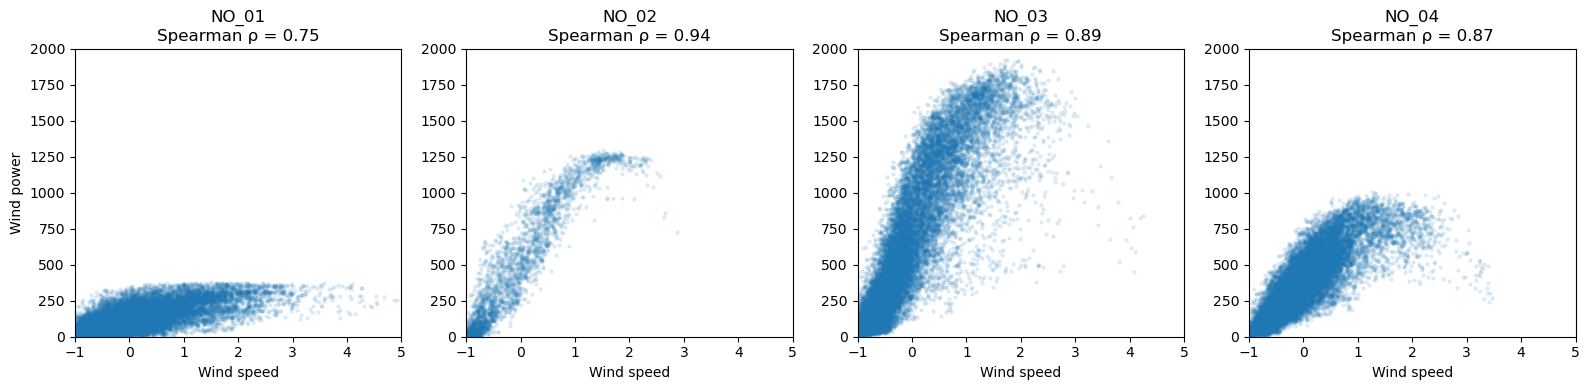

In [12]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=4,
    figsize=(4 * 4, 4),
    sharey=False,
)

for i, ax in enumerate(axes):
    _, S = wind_speed_zones[i].shape
    s = wind_speed_zones[i].mean(axis=-1)
    print(s.min(), s.max())
    p = wind_power_gen_zones[i]
    # s = wind_speed_zones[i].reshape(-1)          # (N*S,)
    # p  = np.repeat(wind_power_gen_zones[i], S)

    rho, _ = spearmanr(s, p, nan_policy="omit")

    ax.scatter(
        s,
        p,
        s=5,
        alpha=0.1,
    )
    ax.set_title(f"NO_0{i+1}\nSpearman ρ = {rho:.2f}")
    ax.set_xlabel("Wind speed")
    ax.set_xlim([-1, 5])
    ax.set_ylim([0, 2000])

axes[0].set_ylabel("Wind power")
plt.tight_layout()
plt.show()

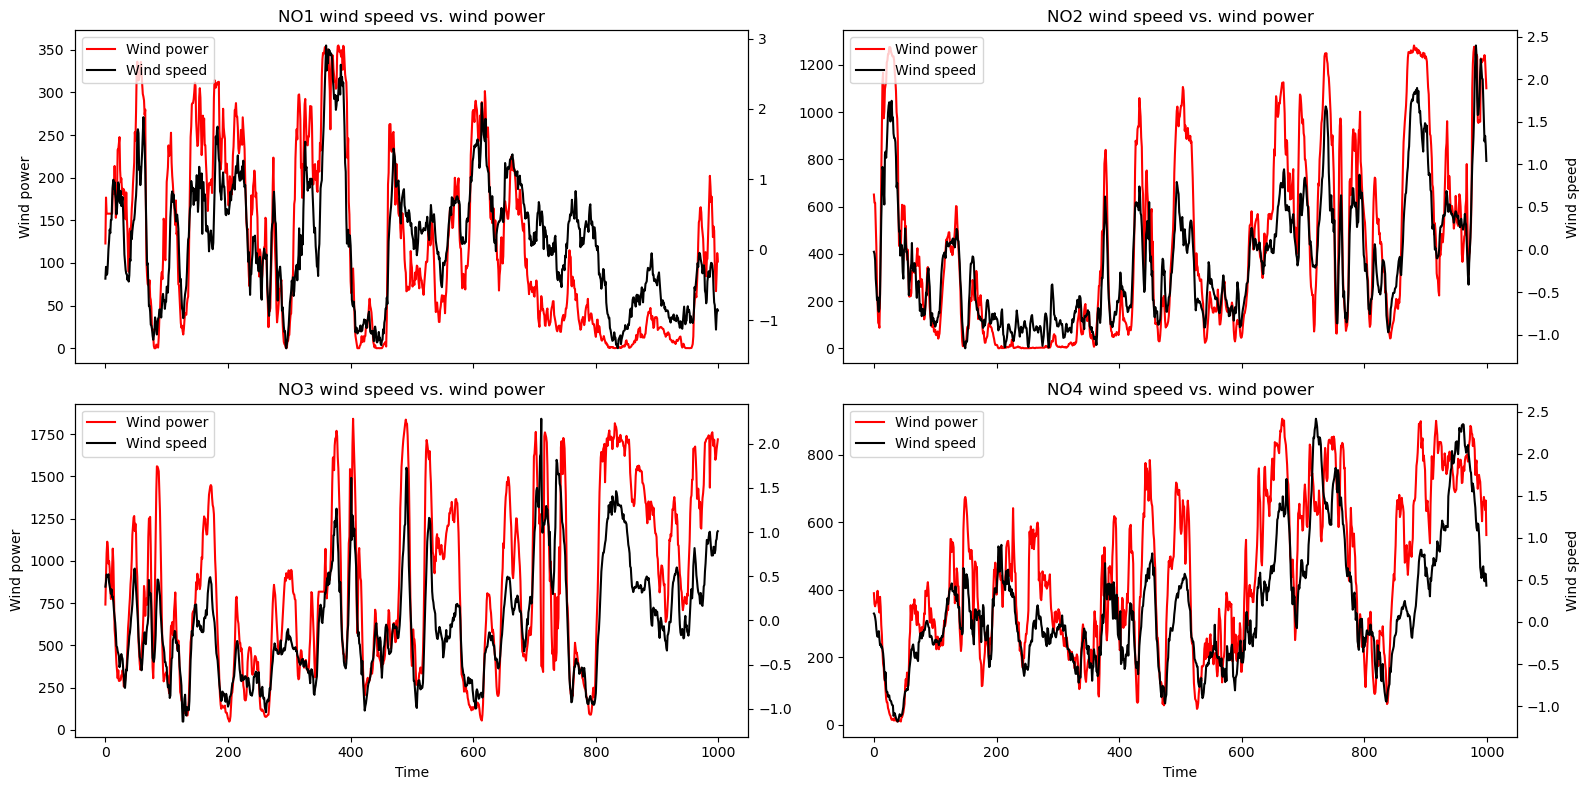

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)

for i, ax in enumerate(axes.ravel()):
    s = wind_speed_zones[i].mean(axis=-1)[:1000]
    p = wind_power_gen_zones[i][:1000]

    x = np.arange(len(s))
    if i >= 2:
        ax.set_xlabel("Time")

    # left axis: wind power
    (l1,) = ax.plot(x, p, color="red", label="Wind power")
    if i % 2 == 0:
        ax.set_ylabel("Wind power")

    # right axis: wind speed
    ax2 = ax.twinx()
    (l2,) = ax2.plot(x, s, color="black", label="Wind speed")
    if i % 2 == 1:
        ax2.set_ylabel("Wind speed")

    # title
    ax.set_title(f"NO{i+1} wind speed vs. wind power")

    # merged legend
    ax.legend(handles=[l1, l2], loc="upper left")


plt.tight_layout()
plt.show()

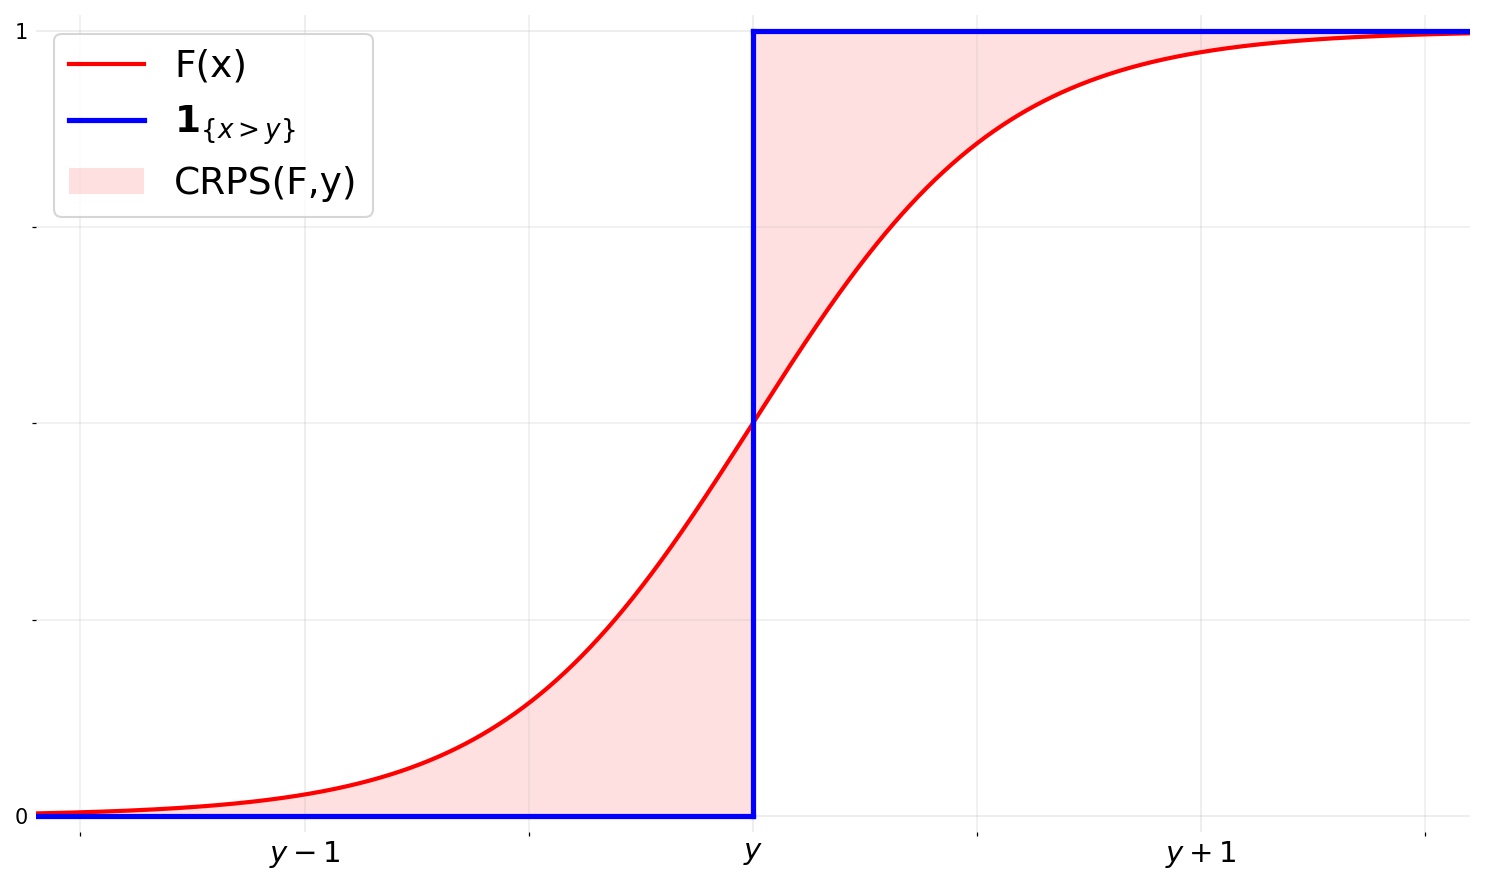

In [14]:
# --- setup ---
y = 0.0  # observation location (the vertical step)
x = np.linspace(y - 1.6, y + 1.6, 1200)

# Smooth CDF F(x): use a logistic CDF to mimic the S-shape in the image
s = 0.28  # scale (smaller => steeper)
F = 1 / (1 + np.exp(-(x - y) / s))

# Indicator 1_{x>y} (step function)
I = (x > y).astype(float)

# --- plot ---
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# F(x) curve (red)
ax.plot(x, F, color="red", lw=2, label="F(x)")

# Step function (blue)
ax.plot([x.min(), y], [0, 0], color="blue", lw=2.5)
ax.plot([y, y], [0, 1], color="blue", lw=2.5)
ax.plot([y, x.max()], [1, 1], color="blue", lw=2.5, label=r"$\mathbf{1}_{\{x>y\}}$")

# Shaded CRPS area = ∫ (F(x) - 1_{x>y})^2 dx (illustrated as area between curves)
# Left of y: between F(x) and 0
maskL = x <= y
ax.fill_between(x[maskL], 0, F[maskL], color="red", alpha=0.12, linewidth=0)

# Right of y: between F(x) and 1
maskR = x >= y
ax.fill_between(
    x[maskR], F[maskR], 1, color="red", alpha=0.12, linewidth=0, label="CRPS(F,y)"
)

# --- styling to match the look ---
ax.set_ylim(-0.02, 1.02)
ax.set_xlim(x.min(), x.max())


ax.grid(True, alpha=0.25, axis="both")
# --- kleinere Abstände einstellen ---
ax.xaxis.set_major_locator(MultipleLocator(1))  # Hauptabstand 1
ax.xaxis.set_minor_locator(MultipleLocator(0.5))  # kleiner Abstand 0.2

ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.25))

# Minor-Grid aktivieren
ax.grid(which="minor", alpha=0.2)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_yticks([0, 1])
ax.set_xticks([y - 1, y, y + 1])
ax.set_xticklabels([r"$y-1$", r"$y$", r"$y+1$"], fontsize=14)

plt.tight_layout()
ax.legend(fontsize=18)
plt.show()

In [15]:
data_dict_zones = {}

for i in range(1, 5):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)

    data_dict_zones[data_cfg.bid_zone] = data

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:722: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

... (15 outputs left out)

QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)


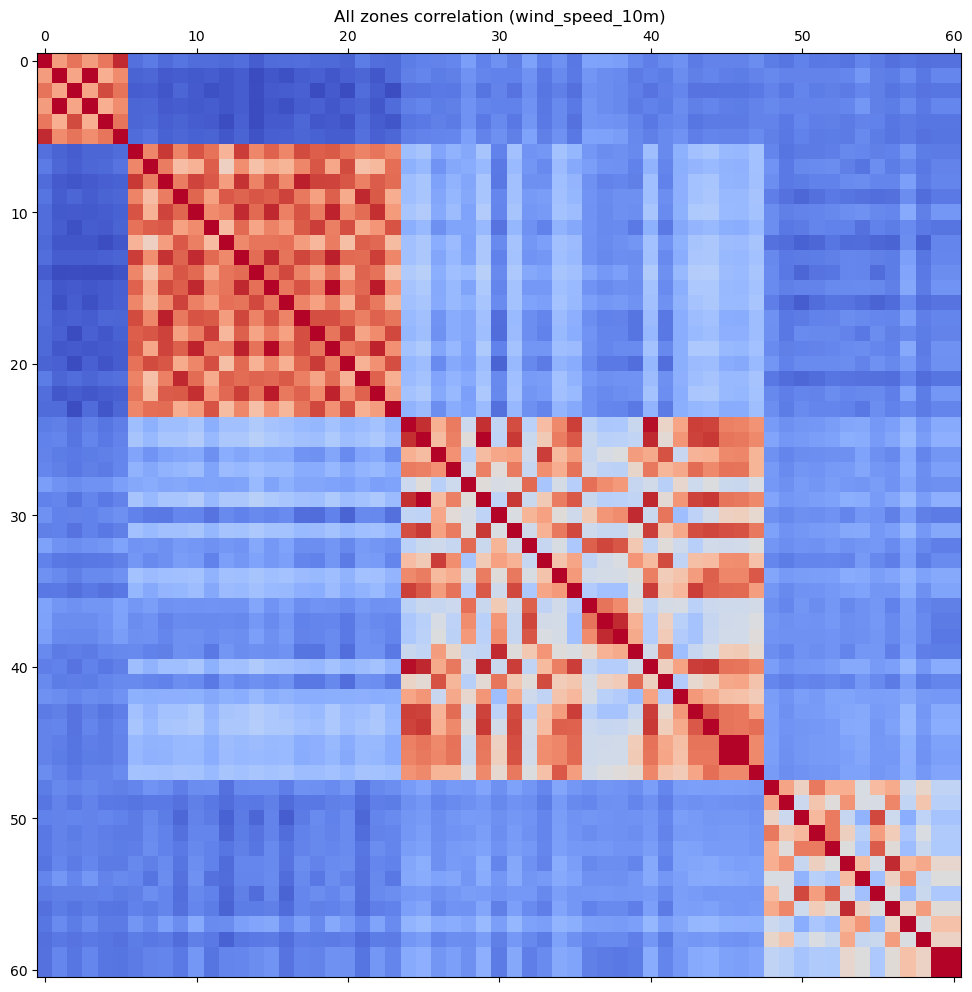

In [21]:
def correlation_across_zones_wrong(feature):
    all_dfs = []

    for z_idx, zone in enumerate(data_dict_zones.keys()):
        z_idx += 1
        X = data_dict_zones[zone]["X_train"]  # (N, S, F)

        N, S, F = X.shape

        speed_idx = data_dict_zones[zone]["feature_cols"].index(feature)

        # unnormalize
        X_all = (
            X[:, :, speed_idx] * data_dict_zones[zone]["scaler_params"]["std"][feature]
            + data_dict_zones[zone]["scaler_params"]["mean"][feature]
        )

        col_names = [f"p{p_idx}_z{z_idx}" for p_idx in range(S)]

        df_zone = pd.DataFrame(X_all, columns=col_names)

        all_dfs.append(df_zone)

    # Alle Zonen horizontal zusammenfügen
    df_all = pd.concat(all_dfs, axis=1)

    corr = df_all.corr()

    plt.figure(figsize=(14, 12))
    plt.matshow(corr, cmap="coolwarm", fignum=0)
    plt.title(f"All zones correlation ({feature})")
    plt.show()


# correlation_across_zones("air_pressure_at_sea_level")
correlation_across_zones_wrong("wind_speed_10m")
# correlation_across_zones("relative_humidity_2m")
# correlation_across_zones("air_temperature_2m")

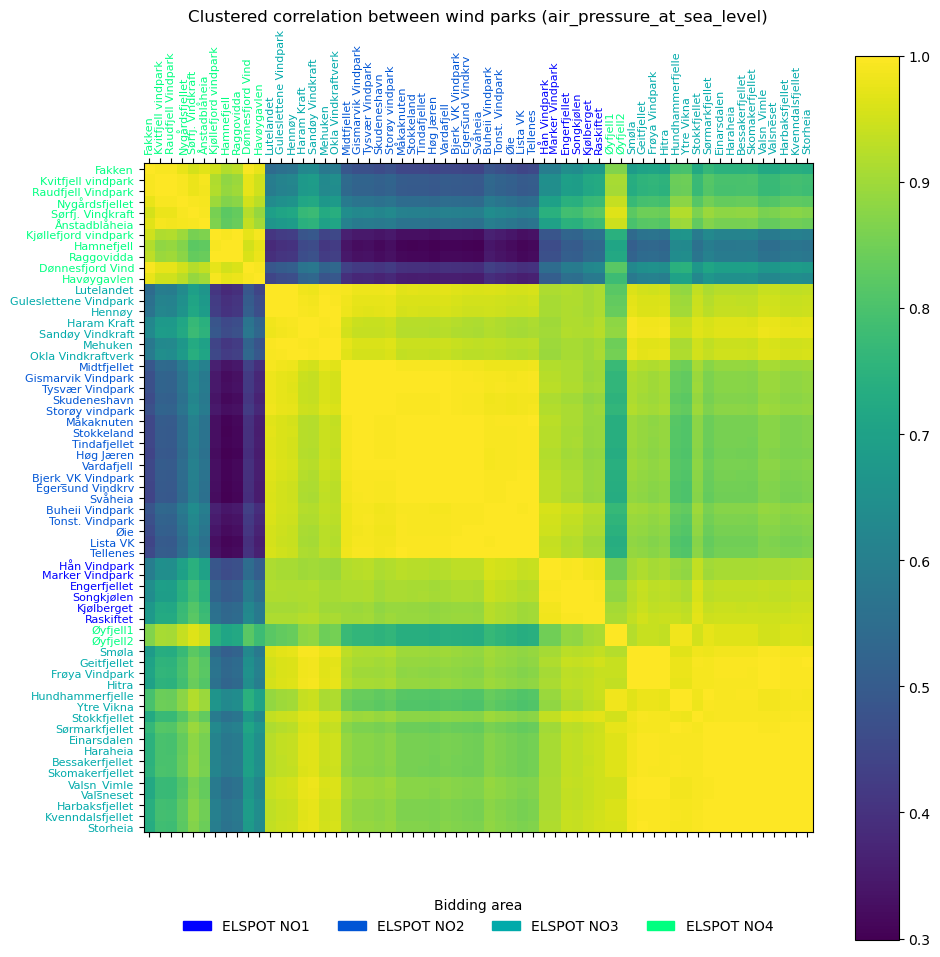

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib.patches as mpatches


def correlation_across_zones(feature):
    weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
    windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
    windparks_unique = (
        windparks[["bidding_area", "substation_name"]]
        .drop_duplicates()
        .set_index("substation_name")
    )
    merged = weather_nowcast.join(windparks_unique[["bidding_area"]], on="windpark")

    dfs = dict(tuple(merged[[feature, "windpark"]].groupby("windpark")))
    df = pd.DataFrame()

    for key in dfs.keys():
        df[key] = dfs[key][feature]

    x = df.to_numpy()

    # Korrelationsmatrix
    C = np.corrcoef(x.T)

    # In Distanz umwandeln
    D = 1 - C

    # condensed form für scipy
    dist = squareform(D, checks=False)

    # Hierarchisches Clustering
    Z = linkage(dist, method="ward")

    # Neue Reihenfolge
    order = leaves_list(Z)

    # Matrix umsortieren
    C_sorted = C[np.ix_(order, order)]

    labels = df.columns.to_numpy()[order]

    zones = windparks_unique["bidding_area"].unique()
    cmap = plt.get_cmap("winter")
    colors = {z: cmap(i / (len(zones) - 1)) for i, z in enumerate(zones)}
    plt.figure(figsize=(10, 10))
    plt.matshow(C_sorted, fignum=0)
    plt.colorbar()
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.yticks(range(len(labels)), labels, fontsize=8)
    ax = plt.gca()

    # X-Labels färben
    for label, tick_x, tick_y in zip(
        labels, ax.get_xticklabels(), ax.get_yticklabels()
    ):
        tick_x.set_color(colors[windparks_unique.loc[label, "bidding_area"]])
        tick_y.set_color(colors[windparks_unique.loc[label, "bidding_area"]])

    # Create legend handles
    handles = [mpatches.Patch(color=colors[z], label=z) for z in zones]

    # Add legend below plot
    ax.legend(
        handles=handles,
        title="Bidding area",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),  # below figure
        ncol=len(zones),  # one row
        frameon=False,
    )

    plt.tight_layout()
    plt.title(f"Clustered correlation between wind parks ({feature})")
    plt.show()


correlation_across_zones("air_pressure_at_sea_level")